# 01 — What Random Really Means

Everything downstream in this project inherits the quality of the numbers coming out of
the generator. Every train-test split, every bootstrap resample, every Monte Carlo
estimate is a transformation of a stream of "random" numbers, so it is worth knowing
whether that stream is any good.

**The question this notebook answers:** how would you *know* if your random number
generator was broken?

The uncomfortable answer is that the obvious checks would not tell you. We will take a
generator that was shipped by IBM, used for a decade of serious scientific work, and is
now the textbook example of a broken generator — and watch it pass a uniformity test and
a correlation test before it finally falls apart.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from src.config import load_settings
from src.generators.prng import MINSTD, RANDU, LCG
from src.generators.quality import (
    chi_square_uniformity,
    lattice_triples,
    plane_count,
    plane_fraction,
    plane_projection,
    serial_correlation,
)
from src.reporting import save_results
from src.visualisation import (
    edge_on_view,
    plot_generator_comparison,
    plot_lattice_3d,
    plot_plane_projection,
    plot_uniformity_histograms,
    save_figure,
)

settings = load_settings()
SEED = 1
N = settings.prng.n_uniform
BINS = settings.prng.chi_square_bins

print(f"seed = {SEED}, n = {N:,}, bins = {BINS}")

seed = 1, n = 100,000, bins = 100


## A generator is a recurrence, not magic

A linear congruential generator is three integers and one line of arithmetic:

$$x_{n+1} = (a \cdot x_n + c) \bmod m$$

Divide by $m$ and you have a number in $[0, 1)$. That is the entire mechanism. The whole
question of whether the output is "random" comes down to the choice of $a$, $c$ and $m$.

We build two, differing only in those constants:

- **MINSTD** ($a = 48271$, $m = 2^{31}-1$), a defensible minimal standard.
- **RANDU** ($a = 65539$, $m = 2^{31}$), shipped by IBM in the 1960s.

In [2]:
good = LCG.from_params(MINSTD, seed=SEED).random(N)
bad = LCG.from_params(RANDU, seed=SEED).random(N)

print(f"MINSTD  first five: {np.array2string(good[:5], precision=4)}")
print(f"RANDU   first five: {np.array2string(bad[:5], precision=4)}")
print(f"\nMINSTD mean {good.mean():.5f}, min {good.min():.5f}, max {good.max():.5f}")
print(f"RANDU  mean {bad.mean():.5f}, min {bad.min():.5f}, max {bad.max():.5f}")

MINSTD  first five: [2.2478e-05 8.5032e-02 6.0135e-01 8.9161e-01 9.6796e-01]
RANDU   first five: [3.0519e-05 1.8311e-04 8.2399e-04 3.2959e-03 1.2360e-02]

MINSTD mean 0.49923, min 0.00000, max 1.00000
RANDU  mean 0.50192, min 0.00002, max 0.99999


Both look entirely reasonable. Means near 0.5, full range covered.

## Test 1: is the distribution uniform?

The first thing anyone checks. Bin the values and compare the counts against what a
uniform distribution predicts, with a chi-square test.

MINSTD  chi-square =   106.81   p = 0.278
RANDU   chi-square =   107.75   p = 0.257

(degrees of freedom = 99; a small p-value would be evidence of non-uniformity)


/workspaces/sampling_101/outputs/figures/01_uniformity_histograms.png


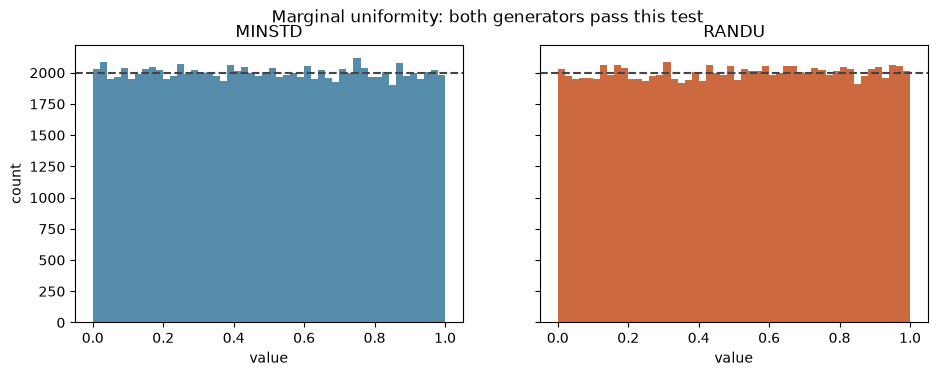

In [3]:
good_chi2, good_p = chi_square_uniformity(good, bins=BINS)
bad_chi2, bad_p = chi_square_uniformity(bad, bins=BINS)

print(f"MINSTD  chi-square = {good_chi2:8.2f}   p = {good_p:.3f}")
print(f"RANDU   chi-square = {bad_chi2:8.2f}   p = {bad_p:.3f}")
print(f"\n(degrees of freedom = {BINS - 1}; a small p-value would be evidence of non-uniformity)")

fig = plot_uniformity_histograms(good, bad, bins=50)
print(save_figure(fig, "01_uniformity_histograms"))

**Both pass.** Neither histogram shows any structure, and neither p-value is anywhere
near significance. If uniformity were the test, both generators would ship.

## Test 2: are consecutive values correlated?

The second obvious check. If $u_i$ told you something about $u_{i+1}$, the stream would
not be independent.

In [4]:
good_serial = serial_correlation(good, lag=1)
bad_serial = serial_correlation(bad, lag=1)
noise_level = 1.0 / np.sqrt(N)

print(f"MINSTD  lag-1 correlation = {good_serial:+.5f}")
print(f"RANDU   lag-1 correlation = {bad_serial:+.5f}")
print(f"\nunder independence these are ~N(0, {noise_level:.5f}), so both are indistinguishable")
print("from zero. Both pass again.")

MINSTD  lag-1 correlation = -0.00404
RANDU   lag-1 correlation = +0.00079

under independence these are ~N(0, 0.00316), so both are indistinguishable
from zero. Both pass again.


## Test 3: plot the pairs

Rather than testing a summary statistic, look at the data. Plot each value against the
one after it.

/workspaces/sampling_101/outputs/figures/01_generator_pairs.png


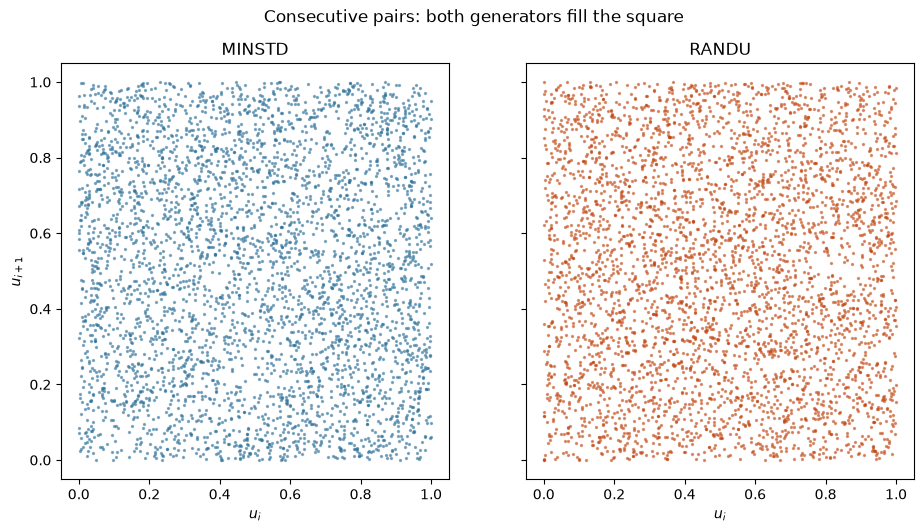

In [5]:
fig = plot_generator_comparison(good, bad)
print(save_figure(fig, "01_generator_pairs"))

Still nothing. Both fill the square. Two statistical tests and a picture, and the
broken generator has passed all three.

## Test 4: add one dimension

Plot *triples* — each value against the next two. First from an ordinary viewing angle:

/workspaces/sampling_101/outputs/figures/01_randu_lattice_generic_view.png


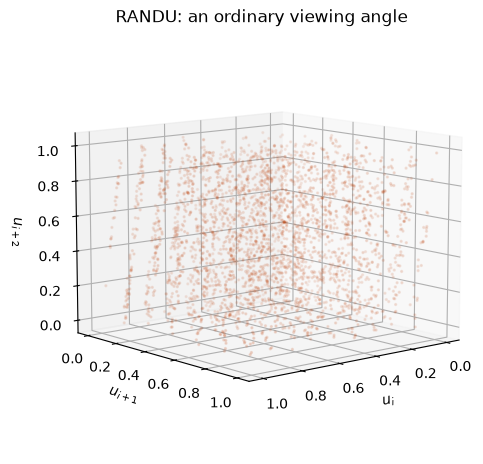

In [6]:
bad_triples = lattice_triples(bad)

fig = plot_lattice_3d(bad_triples, "RANDU: an ordinary viewing angle", view=(10.0, 50.0))
print(save_figure(fig, "01_randu_lattice_generic_view"))

Still a random-looking cloud. Four tests, four passes.

Now rotate. The camera angle below is not guessed — it is computed so the line of sight
is *perpendicular to the normal of RANDU's plane family*, which makes the planes appear
edge-on rather than face-on. `edge_on_view` in `src/visualisation.py` derives it.

edge-on camera: elev = 5.0, azim = 56.77


/workspaces/sampling_101/outputs/figures/01_randu_lattice_3d.png
/workspaces/sampling_101/outputs/figures/01_minstd_lattice_3d.png


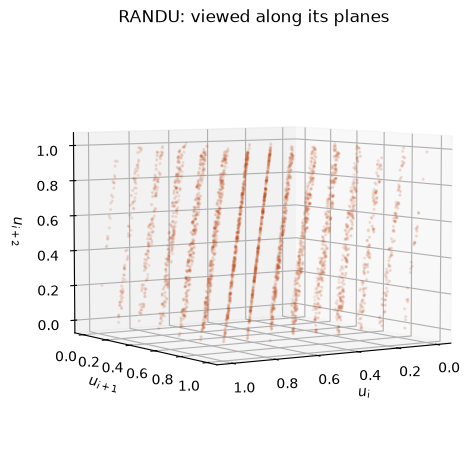

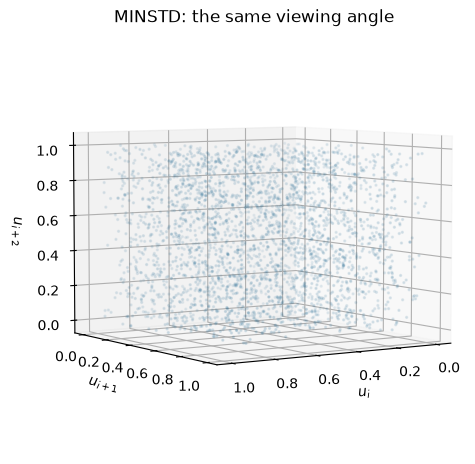

In [7]:
elev, azim = edge_on_view()
print(f"edge-on camera: elev = {elev:.1f}, azim = {azim:.2f}")

fig = plot_lattice_3d(bad_triples, "RANDU: viewed along its planes")
print(save_figure(fig, "01_randu_lattice_3d"))

fig = plot_lattice_3d(
    lattice_triples(good), "MINSTD: the same viewing angle", colour="#2a6f97"
)
print(save_figure(fig, "01_minstd_lattice_3d"))

There it is. RANDU's points are not filling the cube at all — they lie on a small number
of parallel planes with empty space between them. MINSTD's fill it.

Note what that took: the structure stayed invisible until we looked from exactly the
right direction. A picture is not a test, because a picture depends on where you stand.

## Making it quantitative

"It looks striped" is not a test. RANDU's failure has an exact algebraic cause: its
constants satisfy

$$x_{n+2} = 6x_{n+1} - 9x_n \pmod{2^{31}}$$

so the quantity $9u_i - 6u_{i+1} + u_{i+2}$ is *always an integer*. Project the triples
onto that direction and every point must land on a whole number.

MINSTD  triples landing on a plane: 0.000000%
RANDU   triples landing on a plane: 100.000000%

RANDU occupies exactly 15 distinct planes.


/workspaces/sampling_101/outputs/figures/01_plane_projection.png


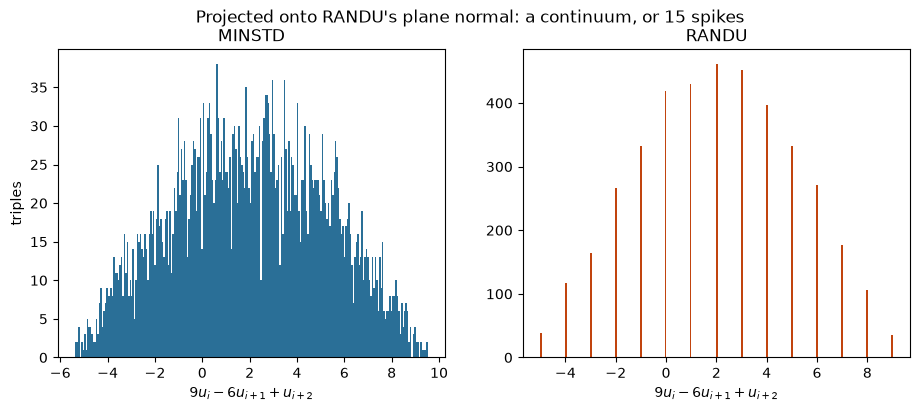

In [8]:
good_projection = plane_projection(good)
bad_projection = plane_projection(bad)

good_fraction = plane_fraction(good, tol=settings.prng.plane_tolerance)
bad_fraction = plane_fraction(bad, tol=settings.prng.plane_tolerance)
bad_planes = plane_count(bad, tol=settings.prng.plane_tolerance)

print(f"MINSTD  triples landing on a plane: {good_fraction:.6%}")
print(f"RANDU   triples landing on a plane: {bad_fraction:.6%}")
print(f"\nRANDU occupies exactly {bad_planes} distinct planes.")

fig = plot_plane_projection(good_projection, bad_projection)
print(save_figure(fig, "01_plane_projection"))

Every single RANDU triple — 100.000000% of them — lies on one of exactly **15** planes.
The three-dimensional structure that the histogram and the correlation test could not
see is total.

## The seed: reproducibility is not randomness

One more distinction worth making. A generator is deterministic: the same seed gives the
same stream, every time. That is a feature, not a bug — it is what makes a result
reproducible.

In [9]:
first = LCG.from_params(MINSTD, seed=42).random(5)
again = LCG.from_params(MINSTD, seed=42).random(5)
different = LCG.from_params(MINSTD, seed=43).random(5)

print(f"seed 42: {np.array2string(first, precision=6)}")
print(f"seed 42: {np.array2string(again, precision=6)}   identical: {np.array_equal(first, again)}")
print(f"seed 43: {np.array2string(different, precision=6)}")

seed 42: [0.000944 0.571363 0.256809 0.447674 0.654139]
seed 42: [0.000944 0.571363 0.256809 0.447674 0.654139]   identical: True
seed 43: [0.000967 0.656395 0.858162 0.339285 0.622095]


**Record the seed, or your result is not reproducible.** Every figure in this project is
generated from a seed stored in `config/settings.yaml`.

## Saving the results

In [10]:
results = {
    "notebook": "01_what_random_really_means",
    "seed": SEED,
    "n_uniform": N,
    "chi_square_bins": BINS,
    "generators": {
        "MINSTD": {
            "params": MINSTD,
            "mean": float(good.mean()),
            "chi_square": good_chi2,
            "chi_square_p": good_p,
            "serial_correlation_lag1": good_serial,
            "plane_fraction": good_fraction,
            "plane_count": plane_count(good, tol=settings.prng.plane_tolerance),
            "verdict": "usable",
        },
        "RANDU": {
            "params": RANDU,
            "mean": float(bad.mean()),
            "chi_square": bad_chi2,
            "chi_square_p": bad_p,
            "serial_correlation_lag1": bad_serial,
            "plane_fraction": bad_fraction,
            "plane_count": bad_planes,
            "verdict": "broken: all triples lie on 15 planes",
        },
    },
    "findings": [
        "Both generators pass a chi-square uniformity test at 100 bins.",
        "Both generators show no lag-1 serial correlation.",
        "Both generators fill the unit square when consecutive pairs are plotted.",
        f"RANDU places {bad_fraction:.1%} of its triples on exactly {bad_planes} planes.",
        "Marginal uniformity is not evidence of randomness; structure must be tested for.",
    ],
    "figures": [
        "01_uniformity_histograms",
        "01_generator_pairs",
        "01_randu_lattice_generic_view",
        "01_randu_lattice_3d",
        "01_minstd_lattice_3d",
        "01_plane_projection",
    ],
}
print(save_results("01_what_random_really_means", results))

/workspaces/sampling_101/outputs/results/01_what_random_really_means.json


## What this bought you

- A generator that passes the tests you would think to run can still be unusable.
  RANDU passed uniformity, passed a correlation test, and looked fine in 2-D.
- The failure only appeared in the third dimension, and only became a *number* once we
  knew the algebraic structure to test for.
- Practical consequence: use your language's modern default (NumPy's `default_rng`, a
  PCG64 generator), not a hand-rolled one, and never `np.random.seed()` with the legacy
  global state.
- Always record the seed.

Next: [02 — Sampling From Any Distribution](02_sampling_from_any_distribution.ipynb),
where these uniform numbers become draws from any distribution you like.